In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import h5py
from pathlib import Path

Select the folder `gw_python` of the repo https://github.com/UCD-GW-Nitrate/gwtools

In [2]:
import tkinter as tk
from tkinter import filedialog

root = tk.Tk()
root.withdraw()
root.attributes('-topmost', True)
gwtools_path = filedialog.askdirectory(title="Select folder of gwtools")

Import the required functions from the gwtools

In [3]:
if gwtools_path not in sys.path:
    sys.path.append(gwtools_path)
if 'mantis_utilities' in sys.modules:
    del sys.modules['mantis_utilities']
import mantis_utilities as mnts

Mantis repository path. \
This is where you clone https://github.com/giorgk/Mantis. \
It is use to set the MantisServer and client executable

In [4]:
root = tk.Tk()
root.withdraw()
root.attributes('-topmost', True)
mantis_repo_path = filedialog.askdirectory(title="Select folder of Mantis repository")

Central Valley Mantis data \
This is the copy of v3_py folder the MantisData box

In [5]:
root = tk.Tk()
root.withdraw()
root.attributes('-topmost', True)
cv_data_path = filedialog.askdirectory(title="Select the folder where the Mantis configuration file is")

Initialize scenario. Generate a scenario dictionary with all available options

In [6]:
scenario = mnts.mantis_inputs()

Set the client executable and temporary files for input/output (this file will be overwritten over and over)

In [7]:
scenario['client'] = (Path(mantis_repo_path) / 'CPP/BIN/MantisClient.exe').as_posix()
scenario['infile'] = (Path(os.getcwd()) / 'temp_inputfile.dat').as_posix()
scenario['outfile'] = (Path(os.getcwd()) / 'temp_output_file.dat').as_posix()
#print(scenario['client'])
#print(scenario['infile'])
#print(scenario['infile'])

Set up scenario in CV. \
Select study area (only one)

In [8]:
scenario['modelArea'] = 'CentralValley'

Select Region division. \
For Central Valley wide simulation use only the following

In [9]:
scenario['bMap'] = 'CentralValley' # To run the entire Central Valley
#scenario['bMap'] = 'Subregions'

Select Regions. \
For Central Valley wide simulation use only the following. No need to specify Regions

In [10]:
scenario['Regions'] = ['CentralValley']
#scenario['Regions'] = ['Subregion1','Subregion2']
#scenario['Regions'] = ['Subregion15']

Saturated Flow parameters. \
For other options see the MantisOptions.md file under MantisData/v3_py


In [11]:
scenario['flowScen'] = 'CVHM2_MAR24_Padj'
scenario['wellType'] = 'VD' # or VD
scenario['por'] = 30; # or any of the 10,20,30,40,50

Unsaturated flow parameters

In [12]:
scenario['unsatScen'] = 'CVHM2_MAR24'
scenario['unsatWC'] = 0.0 #Zero to deactivate Unsaturated travel

Simulation period

In [13]:
scenario['startSimYear'] = 1945
scenario['endSimYear'] = 2200

Setting raster loading

We assume that the raster is defined as a tiff file.

In [14]:
# To read a tiff there are several libraries
# Here I use:
import rasterio

In [22]:
with rasterio.open(Path(cv_data_path) / "../gis_data/CV_Active_Raster.tif") as src:
    arr = src.read(1)          # band 1 as 2D array, shape (rows, cols)
    # arr = src.read()         # all bands, shape (bands, rows, cols)
    transform = src.transform  # affine transform (pixel -> coordinates)
    crs = src.crs
    nodata = src.nodata

In [20]:
# The arr array should typically have the right size
print(arr.shape)

# However if you want to test it compare it with the one use in Central Valley
gs = mnts.mantis_grid_spec('CentralValley')
print(gs)

(12863, 7046)
gridSpec(cornerX=-223300, cornerY=-344600, cellSize=50, Nrows=12863, Ncols=7046)


In [25]:
if nodata is None:
    print('yes')

yes


In [35]:
# Actual files would have loading values so there is no need to run this.
# However the arr variable contains ids.
# Just for demo I will replace the non None values with values that range from north to south from 10 to 200.
# It will be clear later why I do that
mask = ~np.isnan(arr)
nrows, ncols = arr.shape
row_values = np.linspace(10, 200, nrows)
test_load = np.zeros(arr.shape)
gradient = np.broadcast_to(row_values[:, None], arr.shape)
test_load[mask] = gradient[mask]

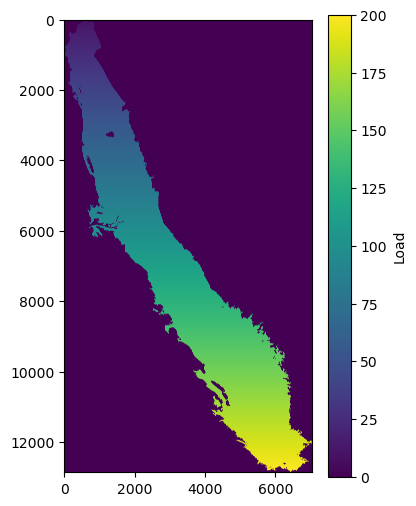

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(4, 6))
im = plt.imshow(test_load, cmap="viridis")
plt.colorbar(im, label="Load")
plt.show()

The array test_load which in real example will be read directly is a 2D np array.\
We need to make it 1D linear array.\
The python api has a function for that but first we need to read the ids to help with the mapping from 2D to 1D and vice versa


In [37]:
idx = mnts.read_raster(Path(cv_data_path) / 'CV_DATA/CVraster_py.h5')

To convert the 2D arra we can use the following

In [39]:
linear_load = mnts.raster_to_linear(test_load, idx)
print(linear_load.shape)

(21155563,)


The following two snippets are not needed. \
I use them just to comfirm that the transformations between 2D and linear data are correct

In [40]:
load_2D_from_Linear = mnts.linear_to_raster(
    linear_data = linear_load,
    idx = idx,
    nrow = gs.Nrows,
    ncol = gs.Ncols
)

The following figure should be identical to the previous one

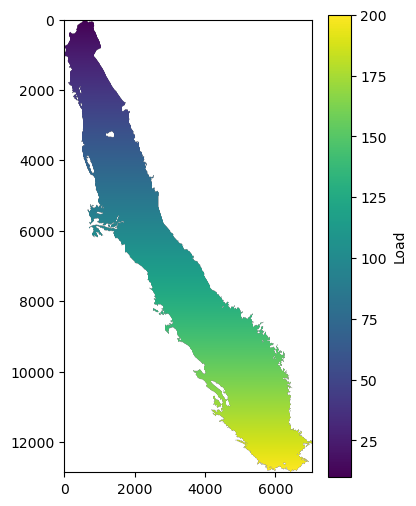

In [43]:
plt.figure(figsize=(4, 6))
im = plt.imshow(load_2D_from_Linear, cmap="viridis")
plt.colorbar(im, label="Load")
plt.show()

For the Mantis Server we need to print the linear load into h5 file. \
The file should be written in a folder accessible to Server. Since you can pass absolute path there is no need to put it under the v3_py folder.

In [45]:
# Here I write it in the current working directory of my notebook
loading_file = Path(os.getcwd()) / "test_load.h5"
mnts.write_linear_data(
    names = ["test_load"],  # This must be always a list. do not pass "test_load" but ["test_load"]. The name doesnt matter
    data = linear_load,
    filename = loading_file
)

HDF5 file written: G:\UCDAVIS\Mantis.wiki\test_load.h5


Now set the related options. \
Always set `scenario['loadScen'] = 'GNLM_Full'` even if its not needed

In [46]:
scenario['loadScen'] = 'GNLM_Full' # this will not be used but is needed to avoid errors
scenario["modifierName"] = loading_file.as_posix()
scenario["modifierType"] = "Replace"
scenario["modifierUnit"] = "CONC"  # Use "MASS" if these are mass-loading values.

Run simulation

In [47]:
scenario['denitMap'] = None
scenario["getids"] = False
scenario["getotherinfo"] = False # getids must be True for this to work
btc, well_info, success = mnts.run_mantis(scenario, return_metadata=True)

In [48]:
def plot_percentiles(x, btc, prctl, title):
    prc_btc = np.percentile(btc, axis=0, q=prctl)
    fig, ax = plt.subplots(figsize=(10, 5))
    for i in range(len(prctl) - 1, -1, -1):
        p = prctl[i]
        ax.plot(x,prc_btc[i, :], label=f"{p}%", linewidth=2)
    ax.set_xlabel('Time (years)')
    ax.set_ylabel('Concentration [mg/l]')
    ax.legend()
    ax.set_title(f"{title}")
    ax.grid()

    return prc_btc

In [49]:
selected_precentiles = [25,50,75,90, 95]
x_time = np.arange(scenario['startSimYear'], scenario['endSimYear'])

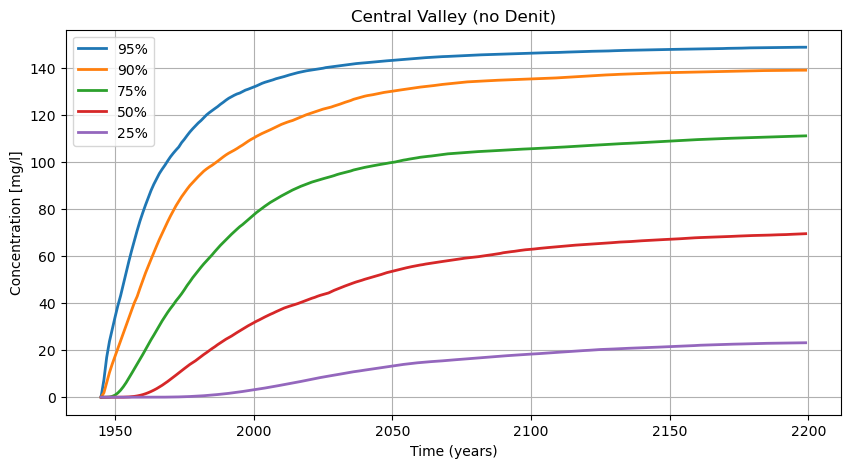

In [50]:
prc_btc = plot_percentiles(x_time, btc, selected_precentiles, "Central Valley (no Denit)")

With denitrification

In [51]:
scenario['denitMap'] = 'DO_05_TD150'
scenario["denitThreshold"] = 0.8
scenario["denitFractionRemoved"] = .90

In [52]:
btc_denit, well_info, success = mnts.run_mantis(scenario, return_metadata=True)

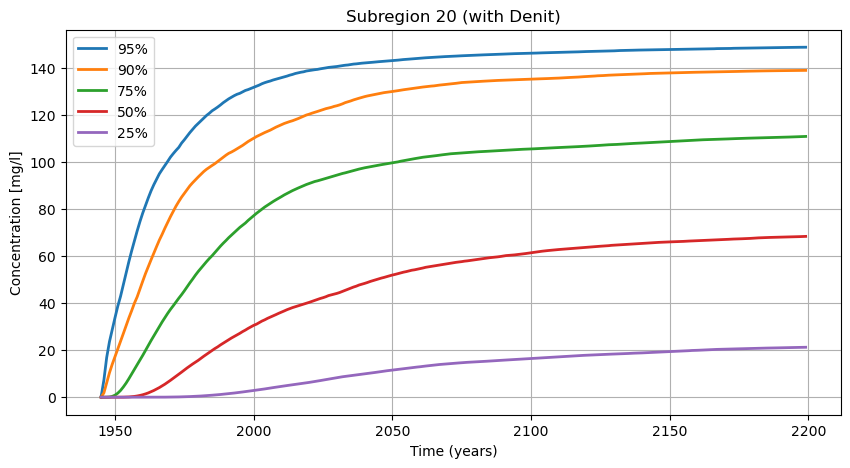

In [53]:
prc_btc_denit = plot_percentiles(x_time, btc_denit, selected_precentiles, "Subregion 20 (with Denit)")
